In [11]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Semilla para que los resultados se repitan en cada ejecución
torch.manual_seed(42)
np.random.seed(42)

In [12]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Configuración aplicada correctamente")

Configuración aplicada correctamente


In [13]:
dataset_path = os.path.join(
    "Bone_Fracture_Binary_Classification",
    "Bone_Fracture_Binary_Classification"
)

for carpeta in ["train", "val", "test"]:
    ruta = os.path.join(dataset_path, carpeta)

    print(f"\n{carpeta.upper()}")

    if os.path.exists(ruta):
        print(os.listdir(ruta))
    else:
        print("No se encontró esta carpeta")



TRAIN
['fractured', 'not fractured']

VAL
['fractured', 'not fractured']

TEST
['fractured', 'not fractured']


In [14]:

# Transformaciones para preparar las radiografías
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Cargar los conjuntos de imágenes
trainset = datasets.ImageFolder(
    os.path.join(dataset_path, "train"),
    transform=transform
)

valset = datasets.ImageFolder(
    os.path.join(dataset_path, "val"),
    transform=transform
)

testset = datasets.ImageFolder(
    os.path.join(dataset_path, "test"),
    transform=transform
)

# Crear los cargadores de datos
trainloader = DataLoader(
    trainset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)
valloader = DataLoader(valset, batch_size=32, shuffle=False)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

# Mostrar información del dataset
print("Clases:", trainset.classes)
print("Imágenes de entrenamiento:", len(trainset))
print("Imágenes de validación:", len(valset))
print("Imágenes de prueba:", len(testset))


Clases: ['fractured', 'not fractured']
Imágenes de entrenamiento: 9246
Imágenes de validación: 829
Imágenes de prueba: 506


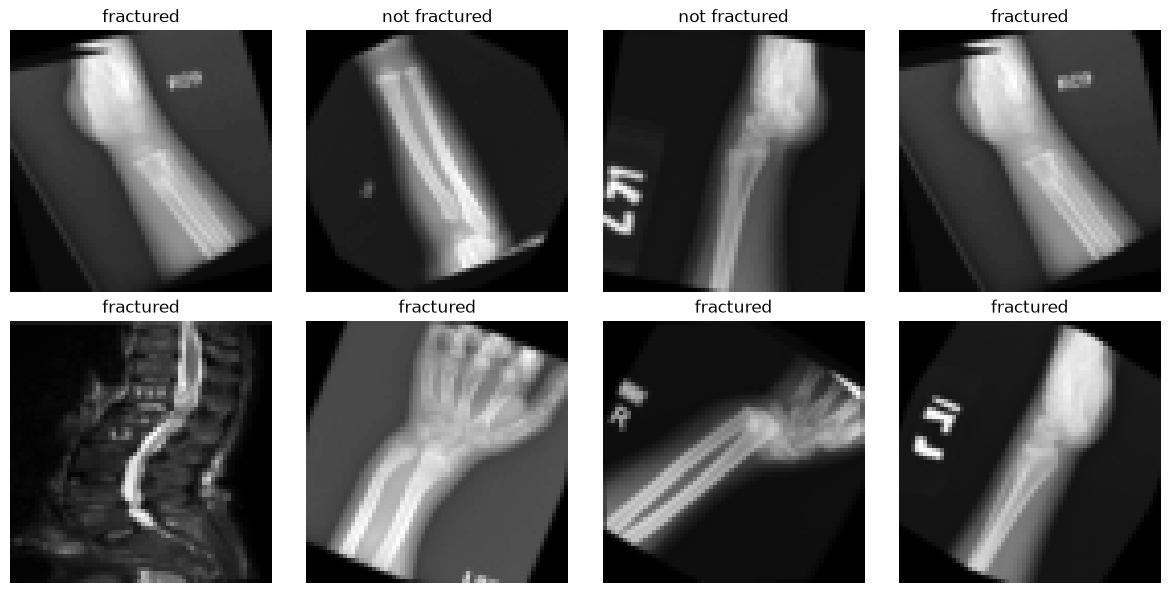

In [15]:

# Obtener un lote de imágenes
images, labels = next(iter(trainloader))

# Mostrar las primeras 8 radiografías
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    clase = trainset.classes[labels[i].item()]
    ax.set_title(clase)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:

import torch.nn as nn

model = nn.Sequential(
    nn.Linear(64 * 64, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

print(model)


Sequential(
  (0): Linear(in_features=4096, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=2, bias=True)
)


In [17]:

# Función de pérdida
criterion = nn.CrossEntropyLoss()

# Optimizador
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

print("Función de pérdida:", criterion)
print("Optimizador:", optimizer)


Función de pérdida: CrossEntropyLoss()
Optimizador: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [18]:

# Obtener un lote de radiografías
images, labels = next(iter(trainloader))

print("Forma original:", images.shape)
print("Forma de las etiquetas:", labels.shape)

# Convertir cada imagen en un vector de 4096 valores
images = images.view(images.shape[0], -1)

print("Forma después de aplanar:", images.shape)

# Realizar una primera predicción
logits = model(images)

print("Forma de la salida:", logits.shape)


Forma original: torch.Size([32, 1, 64, 64])
Forma de las etiquetas: torch.Size([32])
Forma después de aplanar: torch.Size([32, 4096])
Forma de la salida: torch.Size([32, 2])


In [19]:

epochs = 5

train_losses = []

for epoch in range(epochs):
    running_loss = 0

    for images, labels in trainloader:
        # Aplanar las imágenes
        images = images.view(images.shape[0], -1)

        # Limpiar los gradientes anteriores
        optimizer.zero_grad()

        # Propagación hacia adelante
        logits = model(images)

        # Calcular la pérdida
        loss = criterion(logits, labels)

        # Retropropagación
        loss.backward()

        # Actualizar los parámetros
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)

    print(f"Época {epoch + 1}: pérdida = {epoch_loss:.4f}")


Época 1: pérdida = 0.6297
Época 2: pérdida = 0.5329
Época 3: pérdida = 0.4630
Época 4: pérdida = 0.4028
Época 5: pérdida = 0.3402


In [20]:

correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.view(images.shape[0], -1)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = correct / total

print("Imágenes evaluadas:", total)
print(f"Aciertos: {correct}")
print(f"Precisión: {accuracy:.4f}")
print(f"Precisión porcentual: {accuracy * 100:.2f}%")


Imágenes evaluadas: 506
Aciertos: 396
Precisión: 0.7826
Precisión porcentual: 78.26%


In [21]:
# Exactitud en el conjunto de validación (no se reentrena el modelo)
val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in valloader:
        images = images.view(images.shape[0], -1)
        predictions = torch.argmax(model(images), dim=1)
        val_total += labels.size(0)
        val_correct += (predictions == labels).sum().item()

print("Imágenes de validación evaluadas:", val_total)
print(f"Exactitud en validación: {val_correct / val_total * 100:.2f}%")

C:\Users\pc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\PIL\Image.py:1054: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Imágenes de validación evaluadas: 829
Exactitud en validación: 83.96%


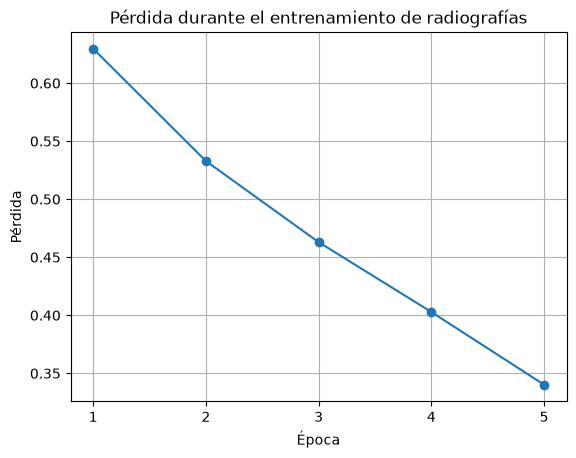

In [22]:

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento de radiografías")
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(True)
plt.show()


##  Evaluación detallada: precisión, recall, F1 y matriz de confusión

La exactitud sola no dice **qué tipo de errores** comete la red. Por eso se calculan las métricas por clase y la matriz de confusión sobre el conjunto de prueba (506 radiografías).

In [23]:

from sklearn.metrics import classification_report, confusion_matrix

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.view(images.shape[0], -1)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

print("Orden de las clases:", testset.classes)

print("\nReporte de clasificación:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=testset.classes,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(all_labels, all_predictions))


Orden de las clases: ['fractured', 'not fractured']

Reporte de clasificación:
               precision    recall  f1-score   support

    fractured       0.82      0.68      0.75       238
not fractured       0.76      0.87      0.81       268

     accuracy                           0.78       506
    macro avg       0.79      0.78      0.78       506
 weighted avg       0.79      0.78      0.78       506


Matriz de confusión:
[[163  75]
 [ 35 233]]


### 🔍 Interpretación de los resultados

**1. Matriz de confusión** (filas = clase real, columnas = clase predicha; orden: `fractured`, `not fractured`)

|  | Predice fractured | Predice not fractured |
|---|---|---|
| **Real: fractured** | 163 (verdaderos positivos) | 75 (falsos negativos) |
| **Real: not fractured** | 35 (falsos positivos) | 233 (verdaderos negativos) |

Los aciertos están en la diagonal: 163 + 233 = 396 de 506, es decir, **78.26 %** de exactitud.

**2. Métricas por clase**

| Clase | Precisión | Recall | F1-score | Cálculo (precisión · recall) |
|---|---|---|---|---|
| fractured | 0.82 | 0.68 | 0.75 | 163/(163+35) · 163/(163+75) |
| not fractured | 0.76 | 0.87 | 0.81 | 233/(233+75) · 233/(233+35) |

- **Precisión:** de todas las radiografías que la red marcó como *fractura*, el 82 % realmente lo era.
- **Recall:** de todas las fracturas reales, la red detectó el 68 %.
- **F1-score:** promedio armónico de precisión y recall; resume el equilibrio entre ambas.

**3. Balance entre clases**

El conjunto de prueba está casi balanceado (238 con fractura y 268 sin fractura), así que la exactitud es una medida razonable. Sin embargo, el rendimiento **no es igual en las dos clases**: el modelo detecta mejor las radiografías sin fractura (recall de 0.87, F1 de 0.81) que las radiografías con fractura (recall de 0.68, F1 de 0.75).

**4. Tipo de error y qué significa**

- Los errores no son simétricos: **75 fracturas sin detectar** (31.5 % de las 238 reales) frente a **35 radiografías sanas marcadas como fractura** (13.1 % de las 268 sanas).
- En un contexto médico el error más grave es el **falso negativo**, porque una fractura inadvertida puede retrasar el tratamiento.
- Por eso el modelo sirve como ejercicio académico de redes neuronales, no como herramienta de diagnóstico.

**5. Exactitud en validación**

En validación la exactitud fue de 83.96 %, mayor que en prueba. El conjunto de validación está desbalanceado (59.3 % sin fractura), así que no es directamente comparable con el de prueba.

**6. Posibles causas del rendimiento**

- Un perceptrón multicapa **aplana** la imagen y pierde la relación espacial entre píxeles.
- Se redujo la imagen a 64×64, lo que borra detalles finos como líneas de fractura delgadas.
- Solo se entrenó durante 5 épocas y la pérdida seguía bajando, así que probablemente el modelo no había convergido.
- El conjunto mezcla distintas regiones del cuerpo, lo que añade variabilidad.

